# ETL con arquitectura medallón: bienestar animal en Cali (CBA/Uaepa) frente a Bogotá (IDPYBA)

Este notebook ejecuta **todo el proceso** paso a paso y muestra, en orden:

1. Contexto y fuentes
2. Datos sin modificar (extracción, capa **bronze**)
3. EDA y problemas encontrados en el dato crudo
4. Limpieza (capa **silver**)
5. Integración con JOIN y KPIs (capa **gold**)
6. Validación y evidencias
7. Resumen y conclusiones



In [1]:
import os
import sys

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import pandas as pd
from IPython.display import Image, display

import src.extract.extract_api as api
import src.extract.extract_csv as extraer_csv
import src.extract.extract_geojson as extraer_geo
import src.quality.quality_checks as calidad
import src.transform.clean_bogota as limpieza_bogota
import src.transform.clean_cali as limpieza_cali
import src.transform.gold_data as gold
import src.utils.graficos as graficos
from src.utils.helpers import cargar_config

pd.set_option("display.width", 200)
cfg = cargar_config()
p, s = cfg["paths"], cfg["sources"]
print("Carpeta de trabajo:", os.getcwd())
print("Proyecto:", cfg["project"]["name"])

Carpeta de trabajo: c:\Users\Laura\Downloads\ETL_Avance_2\Medallon
Proyecto: ETL Bienestar Animal: Cali (CBA/Uaepa) vs Bogota (IDPYBA)


## 1. Contexto y fuentes

En Cali, la Uaepa (a través del Centro de Bienestar Animal, CBA) gestiona solicitudes de abandono, maltrato, citas médicas, esterilizaciones, urgencias y adopciones, pero su registro tiene vacíos geográficos que dificultan la toma de decisiones. Además, se compara con Bogotá (IDPYBA).

| Fuente | Formato | Qué contiene |
|---|---|---|
| **CBA / Uaepa, Cali** | Excel (convertido desde el CSV original de Datos Abiertos Cali) | 17.642 solicitudes, un registro por caso |
| **IDPYBA, Bogotá** | GeoJSON | Atenciones veterinarias de urgencia por localidad (20 localidades, corte 30/06/2025) |
| **Población de Cali por comuna y corregimiento** | **API REST** (Datos Abiertos de Cali, CKAN) | Proyecciones 2006-2020; se usa 2020 |


## 2. EXTRACCIÓN (capa bronze)

Los datos se leen **sin modificar**. El CSV original se conserva en `data/bronze/` y se registra el hash SHA-256 de cada archivo.

### 2.1 Cali (Excel)


In [2]:
bronze_cali = extraer_csv.extraer_cali_excel(s["cali"]["path"], s["cali"]["sheet_name"])
print("Cali (Excel):", bronze_cali.shape)
bronze_cali.head()

2026-11-11 21:35:54 | INFO | BRONZE Cali (Excel): 17642 filas x 5 columnas | sha256=b3dda41a1f7fc2ce


Cali (Excel): (17642, 5)


,_id,Fecha de reporte,Clase de petición,Comuna,Barrio
0,1,2024-01-01T00:00:00,Denuncia,N/D,N/D
1,2,2024-02-01T00:00:00,Adopciones,N/D,N/D
2,3,2024-02-01T00:00:00,Pqr,N/D,N/D
3,4,2024-05-01T00:00:00,Pqr,Comuna 10,Pasoancho
4,5,2024-05-01T00:00:00,Adopciones,Municipio,N/D


### 2.2 Bogotá (GeoJSON)


In [3]:
bronze_bogota = extraer_geo.extraer_bogota(s["bogota"]["path"])
print("Bogotá (GeoJSON):", len(bronze_bogota["features"]), "localidades")
pd.DataFrame([f["properties"] for f in bronze_bogota["features"]]).iloc[:, :8].head()

2026-11-11 21:35:54 | INFO | BRONZE Bogota: 20 features | sha256=1ced21585f46f559


Bogotá (GeoJSON): 20 localidades


,Fecha,Localidad,Atenciones,Digestivo,Infeccioso,Intoxicaci,Neonatolog,Neoplasico
0,2025-06-30,15,6,0,2,0,0,0
1,2025-06-30,06,6,0,2,0,0,0
2,2025-06-30,18,21,0,8,0,0,3
3,2025-06-30,12,3,0,2,0,0,0
4,2025-06-30,13,3,0,1,0,0,1


### 2.3 Población de Cali (API REST)

Se consume el servicio `datastore_search` del portal de Datos Abiertos de Cali y la respuesta original se guarda en `data/bronze/poblacion_comunas_api.json`.


In [4]:
try:
    df_pob_api = api.extraer_poblacion_api(cfg["api_poblacion"])
    print("Registros recibidos:", len(df_pob_api))
    display(df_pob_api.iloc[:6, [1, -1]])   # descripción y último año (2020)
except Exception as e:
    df_pob_api = None
    print("API no disponible:", e)

2026-11-11 21:35:54 | WARNING | API de población sin conexión (403 Client Error: Forbidden for url: https://datos.cali.gov.co/api/3/action/datastore_search?resource_id=63f3e50e-0452-49cf-993d-08dfc2842cb4&limit=500). Se usa snapshot local de bronze: poblacion_comunas_api.json


Registros recibidos: 41


,Descripci√≥n,2020
0,TOTAL CALI,2496346
1,Total Cabecera,2459698
2,Comuna 1,103620
3,Comuna 2,124669
4,Comuna 3,46990
5,Comuna 4,51806


## 3. EDA y problemas del dato crudo


In [5]:
print("Registros Cali:", len(bronze_cali))
for c in bronze_cali.columns:
    vacios = int(bronze_cali[c].isin(["", "N/D"]).sum())
    print(f"{c}: {bronze_cali[c].nunique()} valores distintos | {vacios} vacíos o N/D")

Registros Cali: 17642
_id: 17642 valores distintos | 0 vacíos o N/D
Fecha de reporte: 706 valores distintos | 0 vacíos o N/D
Clase de petición: 9 valores distintos | 22 vacíos o N/D
Comuna: 83 valores distintos | 1796 vacíos o N/D
Barrio: 511 valores distintos | 7785 vacíos o N/D


In [6]:
# Verificación del número de valores distintos de comuna (el Avance 1 habla de 61)
col = next(c for c in bronze_cali.columns if c.lower().startswith("comuna"))
print("Valores distintos en", col, ":", bronze_cali[col].nunique())
print("Tras quitar espacios y pasar a minúsculas:", bronze_cali[col].str.strip().str.lower().nunique())

Valores distintos en Comuna : 83
Tras quitar espacios y pasar a minúsculas: 61


**Problemas encontrados**

1. **Comuna sin diligenciar:** 10,18 % de los registros. **Barrio sin diligenciar:** 44,13 %.
2. **Comunas escritas de muchas formas:** 83 valores distintos (tildes, mayúsculas, errores de digitación) que deben quedar en un catálogo único.
3. **Fechas con error:** 24 registros; 15 tienen el año `0225` (falta un cero) y 9 tienen la fecha vacía.
4. **24 registros sin clasificar** en el tipo de solicitud.
5. **Bogotá es un dato agregado:** 20 filas de un solo corte (30/06/2025), sin registro individual, y solo publica atenciones de urgencia.
6. **Bogotá concentra en Engativá el 69,3 % de las atenciones** porque allí está la infraestructura (UCA), no necesariamente porque allí ocurran más casos.
7. **La población de la API llega solo hasta 2020**, y los casos son de 2024-2026.


## 4. LIMPIEZA (bronze → silver)

- **Cali** (`clean_cali.py`): elimina duplicados por `id`, estandariza comunas y corregimientos en un catálogo único, recupera la comuna desde el barrio solo cuando es inequívoco (mínimo 3 observaciones y 95 % de acuerdo), corrige el año `0225` a 2025 (marcando la fila) y valida las fechas y las categorías.
- **Bogotá** (`clean_bogota.py`): pasa el GeoJSON a una tabla con una fila por localidad (atenciones, especie, sexo, diagnóstico y procedencia).


In [7]:
silver_cali = limpieza_cali.limpiar_cali(bronze_cali, cfg["quality"])
silver_bogota = limpieza_bogota.limpiar_bogota(bronze_bogota)
print("Silver Cali:", silver_cali.shape, "| Silver Bogotá:", silver_bogota.shape)
silver_cali.head()

2026-11-11 21:35:55 | INFO | SILVER Cali: duplicados por id eliminados = 0
2026-11-11 21:35:55 | INFO | SILVER Cali: comunas recuperadas desde barrio = 18
2026-11-11 21:35:55 | INFO | SILVER Cali: 17642 filas | zonas distintas 83 -> 42
2026-11-11 21:35:55 | INFO | SILVER Bogota: 20 localidades | atenciones totales = 947


Silver Cali: (17642, 16) | Silver Bogotá: (20, 39)


,id,fecha,anio,mes,anio_mes,fecha_valida,fecha_corregida,clase,zona,tipo_zona,barrio,comuna_imputada,fecha_raw,clase_raw,comuna_raw,barrio_raw
0,1,2024-01-01,2024,1,2024-01,True,False,Denuncia,Sin dato,sin_dato,Sin dato,False,2024-01-01T00:00:00,Denuncia,N/D,N/D
1,2,2024-02-01,2024,2,2024-02,True,False,Adopciones,Sin dato,sin_dato,Sin dato,False,2024-02-01T00:00:00,Adopciones,N/D,N/D
2,3,2024-02-01,2024,2,2024-02,True,False,PQR,Sin dato,sin_dato,Sin dato,False,2024-02-01T00:00:00,Pqr,N/D,N/D
3,4,2024-05-01,2024,5,2024-05,True,False,PQR,Comuna 10,urbana,Pasoancho,False,2024-05-01T00:00:00,Pqr,Comuna 10,Pasoancho
4,5,2024-05-01,2024,5,2024-05,True,False,Adopciones,Fuera de jurisdicción,fuera_jurisdiccion,Sin dato,False,2024-05-01T00:00:00,Adopciones,Municipio,N/D


### 4.1 Calidad antes y después (OKR 3)


In [8]:
metricas = calidad.metricas_calidad_cali(bronze_cali, silver_cali, cfg["quality"])
metricas

,indicador,antes_bronze,despues_silver,nota
0,registros_totales,17642.00,17642.00,
1,registros_duplicados_por_id,0.00,0.00,se eliminan
2,registros_identicos_sin_id,4117.00,4117.00,informativo: pueden ser solicitudes distintas;...
3,pct_registros_con_comuna,89.81,89.92,meta Avance 1: 98%
4,pct_registros_sin_comuna,10.19,10.08,
5,pct_registros_con_barrio,55.87,55.87,meta Avance 1: 80%
6,pct_registros_sin_barrio,44.13,44.13,
7,valores_distintos_comuna,83.00,42.00,catalogo unico de comunas/corregimientos
8,valores_distintos_clase_peticion,9.00,8.00,
9,registros_con_error_de_fecha,27.00,12.00,antes: invalidas + corregibles; despues: inval...


**Lectura de los resultados:** las metas del Avance 1 (98 % de comuna y 80 % de barrio) **no se alcanzan**: la comuna pasa de 89,81 % a 89,92 % y el barrio se queda en 55,87 %. El pipeline no inventa datos: solo infiere la comuna desde el barrio cuando es inequívoco, y eso recuperó 18 registros. Sí mejoran las fechas con error (27 a 12 tras corregir las 15 con año `0225` y acotar el cierre real a `2025-12-31` para excluir 5 registros de junio de 2025 mal digitados con año `2026`) y el catálogo de comunas (83 a 42 valores). La completitud real depende de que el dato se capture completo en origen.


### 4.2 Reglas de validación


In [9]:
reglas = calidad.validar_pipeline(bronze_cali, silver_cali, silver_bogota, cfg["quality"])
reglas

2026-11-11 21:35:55 | INFO | CALIDAD [OK] Cali: no se pierden registros bronze->silver 17642 -> 17642
2026-11-11 21:35:55 | INFO | CALIDAD [OK] Cali: id unico 
2026-11-11 21:35:55 | INFO | CALIDAD [OK] Cali: clase sin valores fuera del catalogo 
2026-11-11 21:35:55 | INFO | CALIDAD [OK] Cali: fechas validas dentro del rango 
2026-11-11 21:35:55 | INFO | CALIDAD [OK] Cali: fechas invalidas < 1% 0.068%
2026-11-11 21:35:55 | INFO | CALIDAD [OK] Bogota: 20 localidades 20 localidades
2026-11-11 21:35:55 | INFO | CALIDAD [OK] Bogota: sin nulos en atenciones 
2026-11-11 21:35:55 | INFO | CALIDAD [OK] Bogota: especie suma atenciones 
2026-11-11 21:35:55 | INFO | CALIDAD [OK] Bogota: sexo suma atenciones 
2026-11-11 21:35:55 | WARNING | CALIDAD [ADVERTENCIA] Bogota: diagnosticos suman atenciones diferencias en Kennedy (-2), Fontibón (+2), Rafael Uribe Uribe (-1), Ciudad Bolívar (+1)
2026-11-11 21:35:55 | WARNING | CALIDAD [ADVERTENCIA] Bogota: procedencia suman atenciones diferencias en Rafael 

,regla,estado,detalle
0,Cali: no se pierden registros bronze->silver,OK,17642 -> 17642
1,Cali: id unico,OK,
2,Cali: clase sin valores fuera del catalogo,OK,
3,Cali: fechas validas dentro del rango,OK,
4,Cali: fechas invalidas < 1%,OK,0.068%
5,Bogota: 20 localidades,OK,20 localidades
6,Bogota: sin nulos en atenciones,OK,
7,Bogota: especie suma atenciones,OK,
8,Bogota: sexo suma atenciones,OK,
9,Bogota: diagnosticos suman atenciones,ADVERTENCIA,"diferencias en Kennedy (-2), Fontibón (+2), Ra..."


Las dos advertencias son de la fuente de Bogotá: los diagnósticos y la procedencia no suman exactamente las atenciones en algunas localidades (diferencias de 1 o 2).


## 5. INTEGRACIÓN Y KPIs (silver → gold)

**Integración con JOIN:**
- **JOIN 1:** los casos de Cali se unen a `dim_categoria` (muchos a uno) para llevar las categorías de las dos ciudades a una `categoria_comparable`. Solo "Urgencias" es comparable entre ambas.
- **JOIN 2:** el comparativo de ciudades une ambas fuentes por `categoria_comparable`.
- **JOIN 3:** los casos por zona se unen a la población de la API por zona, para calcular la tasa por 10.000 habitantes.


In [10]:
dim = gold.construir_dim_categoria(silver_cali)
dim

,ciudad,categoria_origen,categoria_comparable,comparable
0,Cali,Adopciones,Adopciones,False
1,Cali,Cita médica,Cita médica,False
2,Cali,Denuncia,Denuncia,False
3,Cali,Esterilizaciones,Esterilizaciones,False
4,Cali,PQR,PQR,False
5,Cali,Sin clasificar,Sin clasificar,False
6,Cali,Solicitud de información general,Solicitud de información general,False
7,Cali,Urgencias,Urgencias,True
8,Bogotá,Atenciones de urgencia,Urgencias,True


In [11]:
gold_final = gold.integrar_gold_final(silver_cali, silver_bogota)
print("gold_final:", gold_final.shape)
gold_final.head()

2026-11-11 21:35:55 | INFO | GOLD final: 404 filas (Cali 17642 casos | Bogota 947 atenciones)


gold_final: (404, 9)


,ciudad,nivel_geografico,zona,tipo_zona,categoria,periodo,casos,pct_casos_ciudad,comparable
0,Bogotá,localidad,Antonio Nariño,localidad,Urgencias,2025 (corte 30/06),6,0.634,True
1,Bogotá,localidad,Barrios Unidos,localidad,Urgencias,2025 (corte 30/06),3,0.317,True
2,Bogotá,localidad,Bosa,localidad,Urgencias,2025 (corte 30/06),22,2.323,True
3,Bogotá,localidad,Chapinero,localidad,Urgencias,2025 (corte 30/06),2,0.211,True
4,Bogotá,localidad,Ciudad Bolívar,localidad,Urgencias,2025 (corte 30/06),65,6.864,True


In [12]:
# Población: primero la API; si no está disponible, el archivo local
poblacion = None
cp = cfg.get("api_poblacion", {})
if cp.get("enabled"):
    try:
        poblacion = gold.poblacion_desde_api(api.extraer_poblacion_api(cp), cp["anio"])
    except Exception as e:
        print("API de población no disponible:", e)
if poblacion is None:
    poblacion = gold.cargar_poblacion(s["poblacion_cali"]["path"])
print("Zonas con población:", None if poblacion is None else len(poblacion))

2026-11-11 21:35:56 | WARNING | API de población sin conexión (403 Client Error: Forbidden for url: https://datos.cali.gov.co/api/3/action/datastore_search?resource_id=63f3e50e-0452-49cf-993d-08dfc2842cb4&limit=500). Se usa snapshot local de bronze: poblacion_comunas_api.json
2026-11-11 21:35:56 | INFO | API de población: 1 filas descartadas (no son comuna o corregimiento): ['Otros']
2026-11-11 21:35:56 | INFO | API de población: 37 zonas con población (año 2020)


Zonas con población: 37


In [13]:
k_zona = gold.kpi_casos_por_zona(silver_cali, poblacion)
k_evol = gold.kpi_evolucion_mensual(silver_cali)
k_prio = gold.kpi_priorizacion(k_zona, cfg["gold"]["pesos_priorizacion"])
k_comp = gold.kpi_comparativo_ciudades(silver_cali, silver_bogota, dim)
k_urg = gold.kpi_urgencias_por_zona(silver_cali, silver_bogota)
k_bog = gold.kpi_bogota_detalle(silver_bogota)

# Nuevos KPIs para responder preguntas adicionales de negocio
k_cambio = gold.kpi_cambio_anual_servicios(silver_cali)
k_brecha = gold.kpi_brecha_prevencion_zona(k_zona)
k_barrios = gold.kpi_top_barrios_cali(silver_cali)
k_cal_clase = gold.kpi_calidad_por_clase(silver_cali)
k_semanal = gold.kpi_patron_semanal_cali(silver_cali)
k_bog_sesgo = gold.kpi_bogota_engativa_vs_resto(silver_bogota)

k_zona.head(8)[["zona", "casos_total", "denuncias", "urgencias", "poblacion", "casos_por_10k_hab"]]

,zona,casos_total,denuncias,urgencias,poblacion,casos_por_10k_hab
0,Comuna 20,2310,50,106,71043.0,325.16
1,Sin dato,1779,112,20,NaN,<NA>
2,Comuna 18,1441,68,93,150663.0,95.64
3,Comuna 13,1146,60,69,181084.0,63.29
4,Comuna 14,1084,68,63,181093.0,59.86
5,Comuna 21,961,73,66,121440.0,79.13
6,Comuna 6,936,70,57,198137.0,47.24
7,Comuna 15,846,58,46,174473.0,48.49


### 5.1 Priorización territorial y evolución mensual


In [14]:
k_prio.head(10)[["ranking_prioridad", "ranking_en_tipo_zona", "zona", "tipo_zona", "casos_total",
                 "casos_criticos", "casos_por_10k_hab", "indice_priorizacion"]]

,ranking_prioridad,ranking_en_tipo_zona,zona,tipo_zona,casos_total,casos_criticos,casos_por_10k_hab,indice_priorizacion
0,1,1,Comuna 20,urbana,2310,156,325.16,99.1
1,2,2,Comuna 18,urbana,1441,161,95.64,61.9
2,3,3,Comuna 21,urbana,961,139,79.13,47.8
3,4,4,Comuna 13,urbana,1146,129,63.29,47.5
4,5,5,Comuna 14,urbana,1084,131,59.86,46.5
5,6,6,Comuna 6,urbana,936,127,47.24,41.9
6,7,7,Comuna 15,urbana,846,104,48.49,36.2
7,8,8,Comuna 1,urbana,717,104,69.2,36.0
8,9,1,Villacarmelo,rural,118,20,1442.54,35.7
9,10,9,Comuna 17,urbana,415,119,26.59,29.3


In [15]:
k_evol[["anio_mes", "casos_total", "variacion_pct_mensual"]]

,anio_mes,casos_total,variacion_pct_mensual
0,2024-01,1300,<NA>
1,2024-02,1292,-0.62
2,2024-03,801,-38.0
3,2024-04,850,6.12
4,2024-05,1163,36.82
5,2024-06,973,-16.34
6,2024-07,1212,24.56
7,2024-08,1124,-7.26
8,2024-09,896,-20.28
9,2024-10,758,-15.4


### 5.2 Cali frente a Bogotá


In [16]:
display(k_comp)
k_urg.head(10)

,categoria_comparable,casos_cali_total,casos_cali_hasta_corte_bogota,casos_bogota_corte_2025_06_30,comparable,nota
0,Urgencias,879,643,947.0,True,Unica categoria comparable. Periodos distintos...
1,Adopciones,61,59,NaN,False,Solo Cali
2,Cita médica,4453,2942,NaN,False,Solo Cali
3,Denuncia,1312,1025,NaN,False,Solo Cali
4,Esterilizaciones,1971,1920,NaN,False,Solo Cali
5,PQR,8935,8239,NaN,False,Solo Cali
6,Sin clasificar,24,23,NaN,False,Solo Cali
7,Solicitud de información general,7,7,NaN,False,Solo Cali


,ciudad,zona,urgencias,pct_ciudad,pct_atendidas_en_uca
0,Bogotá,Engativá,656,69.27,97.7
1,Bogotá,Ciudad Bolívar,65,6.86,0.0
2,Bogotá,Usme,33,3.48,0.0
3,Bogotá,Kennedy,25,2.64,0.0
4,Bogotá,Santa Fe,22,2.32,4.5
5,Bogotá,Bosa,22,2.32,0.0
6,Bogotá,Fontibón,22,2.32,0.0
7,Bogotá,Rafael Uribe Uribe,21,2.22,0.0
8,Bogotá,San Cristóbal,17,1.80,0.0
9,Bogotá,Suba,13,1.37,0.0


In [17]:
k_bog

,dimension,categoria,casos,pct_sobre_atenciones
0,diagnostico,otros,528,55.76
1,diagnostico,infeccioso,161,17.00
2,diagnostico,ortopedico,115,12.14
3,diagnostico,politraumatismo,64,6.76
4,diagnostico,neoplasico,27,2.85
5,diagnostico,neurologico,18,1.90
6,diagnostico,digestivo,13,1.37
7,diagnostico,respiratorio,8,0.84
8,diagnostico,cardiologico,5,0.53
9,diagnostico,reproductivo,3,0.32


### 5.3 Nuevas Preguntas de Negocio y Hallazgos Accionables

A partir de los datos procesados en la capa **Gold**, se formulan y responden 6 preguntas adicionales de negocio:

1. **¿Cómo cambió la composición de la demanda ciudadana y la oferta operativa del CBA entre 2024 y 2025?**
   - **Hallazgo:** En 2024 predominaban las **PQR** (62,3 % del mix, 7.399 casos) y las jornadas de **Esterilizaciones** (15,4 %, 1.822 casos). En 2025 el modelo dio un giro hacia la atención clínica reactiva: **Citas médicas subió +81,3 %** (pasando al **49,8 %** de toda la operación) y **Urgencias creció +137,7 %** (de 260 a 618 casos, 10,7 % del total), mientras que las **Esterilizaciones cayeron un -91,8 %** (solo 149 en 2025) y las **Adopciones un -94,8 %** (de 58 a 3).
2. **¿En qué comunas existe un déficit de prevención (esterilizaciones) frente al volumen de casos críticos (denuncias + urgencias)?**
   - **Hallazgo:** La demanda se divide en dos perfiles territoriales opuestos: en comunas de estratos medios/altos como **Comuna 17** (112 denuncias, la más alta de Cali; `ratio_prevencion_criticos = 0,31`), **Comuna 2** (73 denuncias, ratio `0,37`) y **Comuna 22** (41,8 % de sus casos son denuncias, ratio `0,17`), el ciudadano acude al CBA principalmente para **denunciar maltrato o tenencia irregular**, no para solicitar servicios gratuitos. En cambio, **Comuna 20** (Siloé) registra solo 2,2 % de denuncias pero lidera urgencias (106), citas médicas (824) y esterilizaciones (321, ratio `2,06`). También hay déficit preventivo en **Comuna 1** (ratio `0,69`), **Comuna 9** (`0,57`) y **Comuna 12** (`0,73`).
3. **¿Cuáles son los barrios específicos ("hotspots") que concentran más casos críticos en Cali para focalizar brigadas puerta a puerta?**
   - **Hallazgo:** **Siloé (Comuna 20)** concentra por sí solo **662 solicitudes** (6,7 % de todos los registros con barrio de la ciudad) y **78 casos críticos** (53 urgencias + 25 denuncias), superando a 15 comunas completas. Le siguen **Terrón Colorado (Comuna 1)** con 53 casos críticos (34 urgencias + 19 denuncias), **Los Chorros (Comuna 18)** con 32 críticos, y en el oriente **Manuela Beltrán (Comuna 14)** y **Ciudad Córdoba (Comuna 15)** con 22 críticos cada uno. En el sur destaca **Valle del Lili (Comuna 17)** con 15 críticos (14 denuncias de 23 casos totales).
4. **¿En qué canales o tipos de solicitud se pierde más información geográfica (comuna y barrio) que impide cumplir el OKR 3?**
   - **Hallazgo:** El **81,2 % de todos los registros sin comuna** (1.444 de 1.779) proviene de **PQR**. En **Esterilizaciones**, la comuna casi siempre se anota (solo 1,8 % sin comuna), pero **el 67,1 % carece de barrio** (1.322 casos sin barrio) porque en las jornadas masivas solo se registra la comuna del operativo. En cambio, **Urgencias** (2,3 % sin comuna, 14,3 % sin barrio) y **Cita médica** (3,0 % sin comuna, 20,2 % sin barrio) tienen alta completitud. Hacer obligatorio el barrio en formularios de PQR y planillas de esterilización resolvería el **80,2 % de los vacíos de barrio**.
5. **¿Cómo se comporta la carga operativa según el día de la semana?**
   - **Hallazgo:** El **80,6 % de las solicitudes** ingresa de lunes a viernes (pico los **martes con 3.052 casos** y **miércoles con 2.886**). Los fines de semana baja el volumen total, pero el **sábado** alcanza la mayor proporción relativa de **Esterilizaciones (14,5 % de los casos del día)** por las brigadas comunitarias de fin de semana.
6. **Si aislamos el sesgo de infraestructura de Engativá (sede de la UCA) en Bogotá, ¿cuál es el verdadero perfil clínico y canal de ingreso en las otras 19 localidades?**
   - **Hallazgo:** En **Engativá** (656 atenciones, 69,3 % de Bogotá), el **97,7 % ingresa por UCA** y el **79,7 % se registra con diagnóstico genérico "Otros"**. Al aislar las **otras 19 localidades (291 atenciones)**, se revela el perfil real de urgencias en territorio: el **84,9 % ingresa por reporte ciudadano directo**, el **7,2 % por Brigadas** y el **7,2 % por Escuadrón Anticrueldad**; clínicamente dominan las patologías **Infecciosas (47,1 %, 137 casos)** y el **Politraumatismo / atropellamiento (20,6 %, 60 casos)**, y la proporción de **felinos sube del 23,3 % al 33,0 %**.


In [18]:
display(k_cambio)
display(k_brecha.head(10))
display(k_barrios.head(10))
display(k_cal_clase)
display(k_semanal)
display(k_bog_sesgo.head(12))

,clase,casos_2024,casos_2025,pct_mix_2024,pct_mix_2025,cambio_puntos_mix,variacion_abs,variacion_pct
0,Cita médica,1581,2866,13.32,49.78,36.46,1285,81.3
1,PQR,7399,1532,62.32,26.61,-35.71,-5867,-79.3
2,Urgencias,260,618,2.19,10.73,8.54,358,137.7
3,Denuncia,724,587,6.1,10.2,4.1,-137,-18.9
4,Esterilizaciones,1822,149,15.35,2.59,-12.76,-1673,-91.8
5,Adopciones,58,3,0.49,0.05,-0.44,-55,-94.8
6,Sin clasificar,22,2,0.19,0.03,-0.16,-20,-90.9
7,Solicitud de información general,7,0,0.06,0.0,-0.06,-7,-100.0


,zona,tipo_zona,casos_total,casos_criticos,denuncias,urgencias,esterilizaciones,citas_medicas,pct_denuncias,pct_urgencias,pct_esterilizaciones,denuncias_por_10k_hab,urgencias_por_10k_hab,ratio_prevencion_criticos,perfil_demanda
0,Comuna 18,urbana,1441,161,68,93,193,381,4.7,6.5,13.4,4.51,6.17,1.2,Balance intermedio prevención/criticidad
1,Comuna 20,urbana,2310,156,50,106,321,824,2.2,4.6,13.9,7.04,14.92,2.06,Alta cobertura relativa de esterilización
2,Comuna 21,urbana,961,139,73,66,122,228,7.6,6.9,12.7,6.01,5.43,0.88,Balance intermedio prevención/criticidad
3,Comuna 14,urbana,1084,131,68,63,137,325,6.3,5.8,12.6,3.75,3.48,1.05,Balance intermedio prevención/criticidad
4,Comuna 13,urbana,1146,129,60,69,143,326,5.2,6.0,12.5,3.31,3.81,1.11,Balance intermedio prevención/criticidad
5,Comuna 6,urbana,936,127,70,57,113,241,7.5,6.1,12.1,3.53,2.88,0.89,Balance intermedio prevención/criticidad
6,Comuna 17,urbana,415,119,112,7,37,64,27.0,1.7,8.9,7.18,0.45,0.31,Foco en denuncias de maltrato/tenencia (baja e...
7,Comuna 15,urbana,846,104,58,46,114,192,6.9,5.4,13.5,3.32,2.64,1.1,Balance intermedio prevención/criticidad
8,Comuna 1,urbana,717,104,55,49,72,211,7.7,6.8,10.0,5.31,4.73,0.69,Déficit preventivo frente a casos críticos
9,Comuna 2,urbana,364,89,73,16,33,65,20.1,4.4,9.1,5.86,1.28,0.37,Foco en denuncias de maltrato/tenencia (baja e...


,ranking_critico,zona,tipo_zona,barrio,casos_total,denuncias,urgencias,esterilizaciones,citas_medicas,pqr,casos_criticos,pct_sobre_barrios_identificados
0,1,Comuna 20,urbana,Siloé,662,25,53,53,273,258,78,6.72
1,2,Comuna 1,urbana,Terrón Colorado,288,19,34,19,112,103,53,2.92
2,3,Comuna 18,urbana,Los Chorros,236,9,23,28,101,73,32,2.39
3,4,Comuna 14,urbana,Manuela Beltrán,121,12,10,8,42,49,22,1.23
4,5,Comuna 15,urbana,Ciudad Córdoba,101,15,7,6,23,50,22,1.02
5,6,Comuna 18,urbana,Alto Nápoles,101,7,12,7,30,45,19,1.02
6,7,Comuna 18,urbana,Meléndez,95,9,9,3,33,41,18,0.96
7,8,Comuna 16,urbana,Antonio Nariño,93,11,7,0,23,52,18,0.94
8,9,Comuna 20,urbana,Brisas De Mayo,172,4,13,16,76,62,17,1.74
9,10,Comuna 6,urbana,Ciudadela Floralia,116,5,11,5,63,31,16,1.18


,clase,casos_total,sin_comuna,sin_barrio,comunas_recuperadas,pct_sin_comuna_en_clase,pct_sin_barrio_en_clase,aporte_al_total_sin_comuna_pct,aporte_al_total_sin_barrio_pct
0,PQR,8935,1444,4921,9,16.16,55.08,81.17,63.21
1,Esterilizaciones,1971,35,1322,0,1.78,67.07,1.97,16.98
2,Cita médica,4453,133,901,5,2.99,20.23,7.48,11.57
3,Denuncia,1312,112,449,4,8.54,34.22,6.30,5.77
4,Urgencias,879,20,126,0,2.28,14.33,1.12,1.62
5,Adopciones,61,17,44,0,27.87,72.13,0.96,0.57
6,Sin clasificar,24,17,19,0,70.83,79.17,0.96,0.24
7,Solicitud de información general,7,1,3,0,14.29,42.86,0.06,0.04


,orden_dia,dia_semana,tipo_dia,casos_total,pct_total_semanal,citas_medicas,pqr,esterilizaciones,denuncias,urgencias,pct_esterilizaciones_en_dia
0,1,Lunes,Hábil,2764,15.68,693,1440,279,212,130,10.09
1,2,Martes,Hábil,3052,17.31,762,1566,337,210,152,11.04
2,3,Miércoles,Hábil,2886,16.37,710,1481,338,202,139,11.71
3,4,Jueves,Hábil,2803,15.90,778,1334,330,227,116,11.77
4,5,Viernes,Hábil,2699,15.31,723,1337,277,187,165,10.26
5,6,Sábado,Fin de semana,1856,10.53,406,943,269,136,94,14.49
6,7,Domingo,Fin de semana,1570,8.91,375,830,141,137,82,8.98


,dimension,categoria,casos_engativa_uca,pct_engativa_uca,casos_resto_19_localidades,pct_resto_19_localidades,diferencia_puntos_pct
0,diagnostico,infeccioso,24,3.66,137,47.08,43.42
1,diagnostico,politraumatismo,4,0.61,60,20.62,20.01
2,diagnostico,ortopedico,78,11.89,37,12.71,0.82
3,diagnostico,neoplasico,7,1.07,20,6.87,5.80
4,diagnostico,neurologico,3,0.46,15,5.15,4.69
5,diagnostico,digestivo,8,1.22,5,1.72,0.50
6,diagnostico,otros,523,79.73,5,1.72,-78.01
7,diagnostico,cardiologico,2,0.30,3,1.03,0.73
8,diagnostico,renal,0,0.00,2,0.69,0.69
9,diagnostico,reproductivo,1,0.15,2,0.69,0.54


## 6. VALIDACIÓN Y EVIDENCIAS

Las gráficas se guardan como evidencia en `evidencias/`, junto con `validaciones_calidad.csv`.


2026-11-11 21:35:57 | INFO | Evidencia grafica: evidencias/01_casos_por_comuna.png
2026-11-11 21:35:57 | INFO | Evidencia grafica: evidencias/02_evolucion_mensual.png
2026-11-11 21:35:58 | INFO | Evidencia grafica: evidencias/03_urgencias_cali_vs_bogota.png
2026-11-11 21:35:58 | INFO | Evidencia grafica: evidencias/04_calidad_antes_despues.png
2026-11-11 21:35:58 | INFO | Evidencia grafica: evidencias/05_cambio_mix_2024_vs_2025.png
2026-11-11 21:35:58 | INFO | Evidencia grafica: evidencias/06_brecha_prevencion_vs_criticos.png
2026-11-11 21:35:59 | INFO | Evidencia grafica: evidencias/07_top_barrios_criticos_cali.png
2026-11-11 21:35:59 | INFO | Evidencia grafica: evidencias/08_bogota_sesgo_uca_vs_resto.png


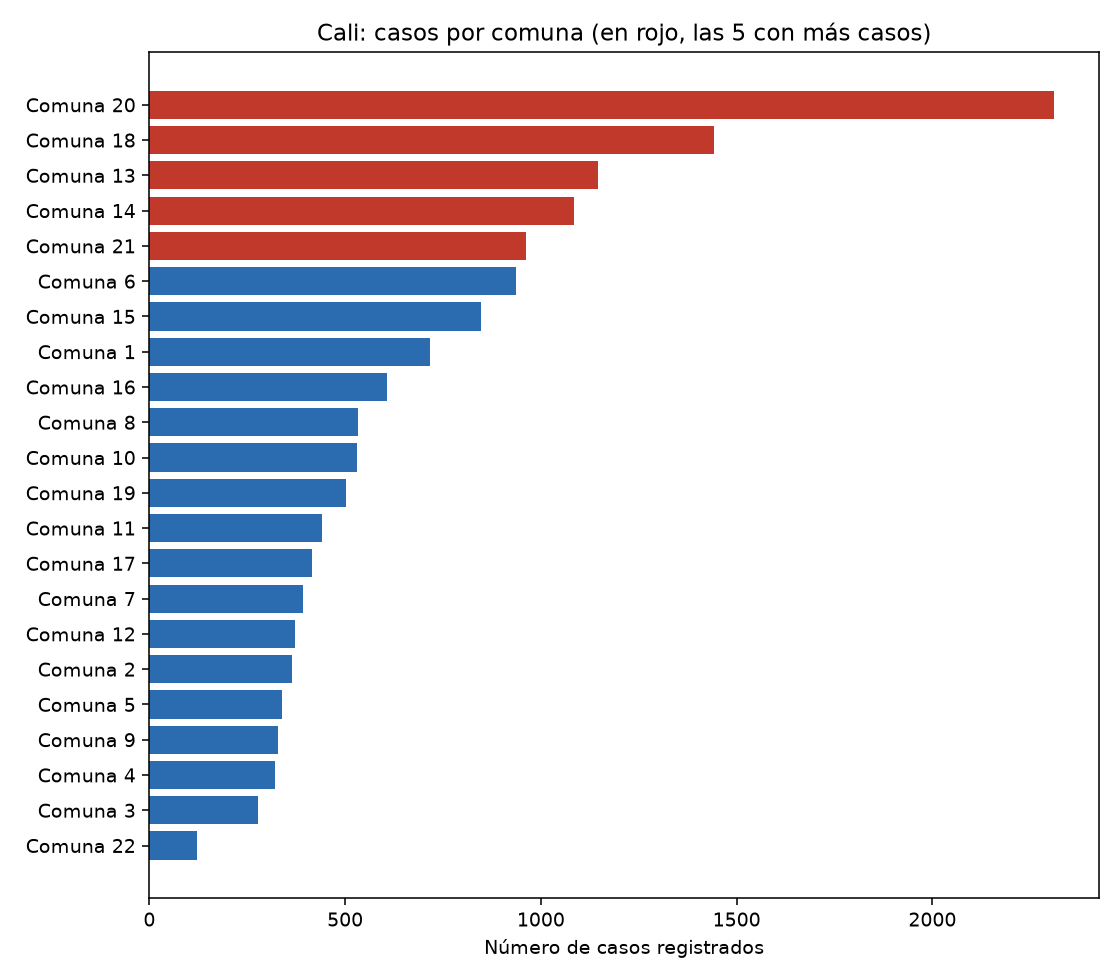

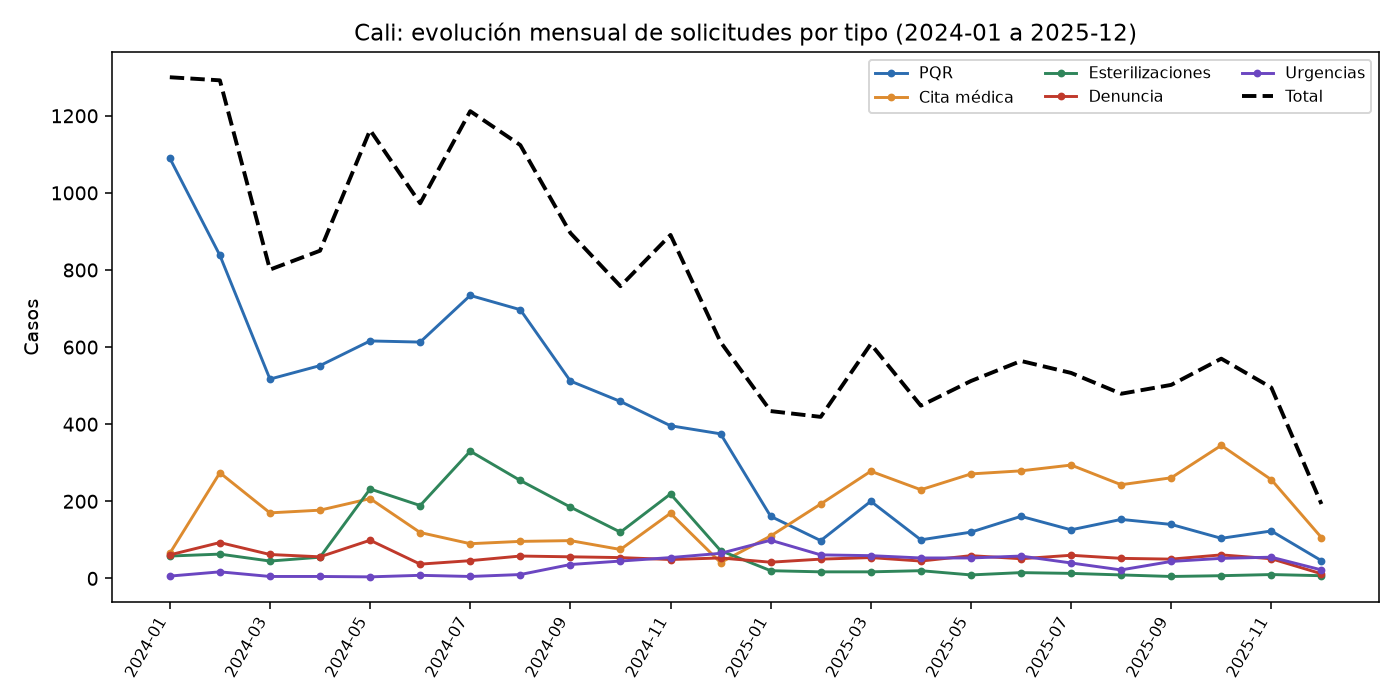

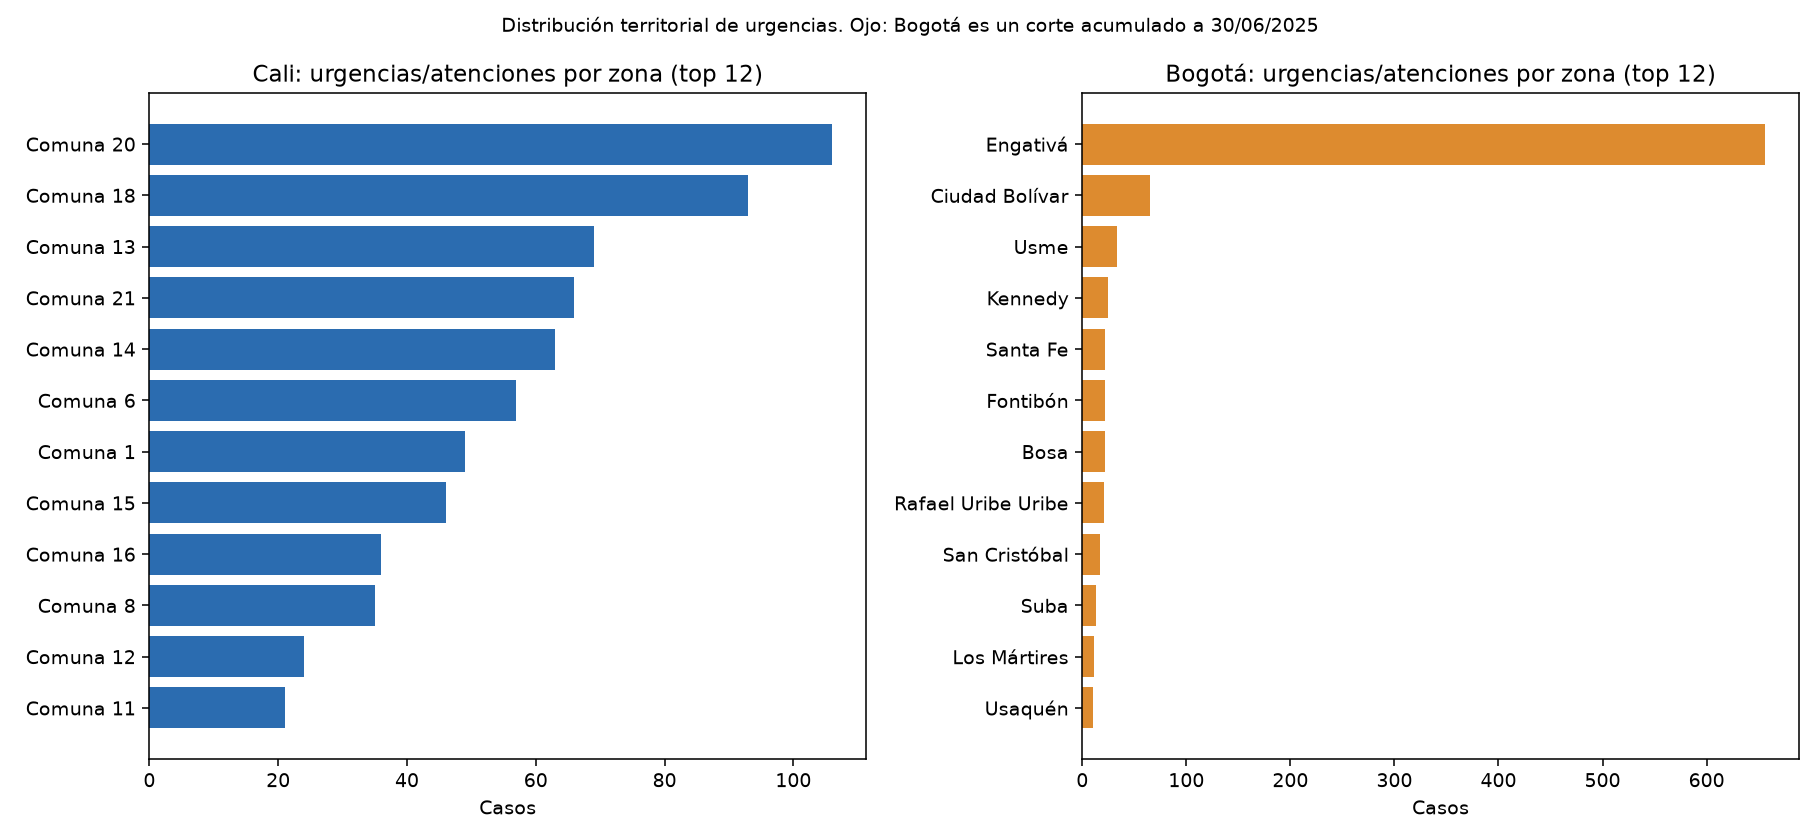

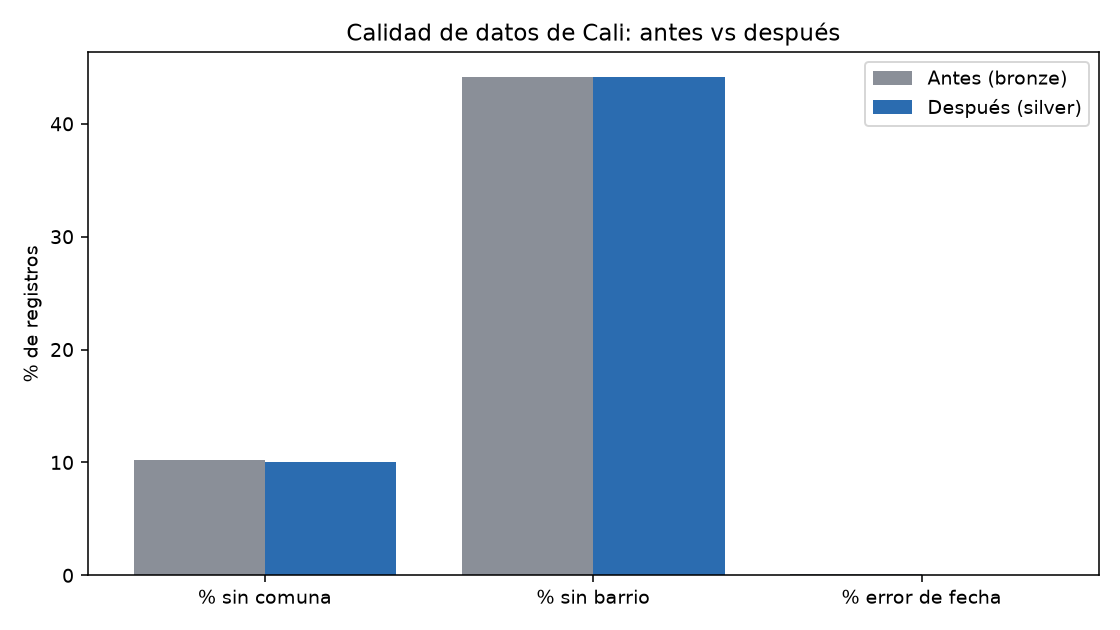

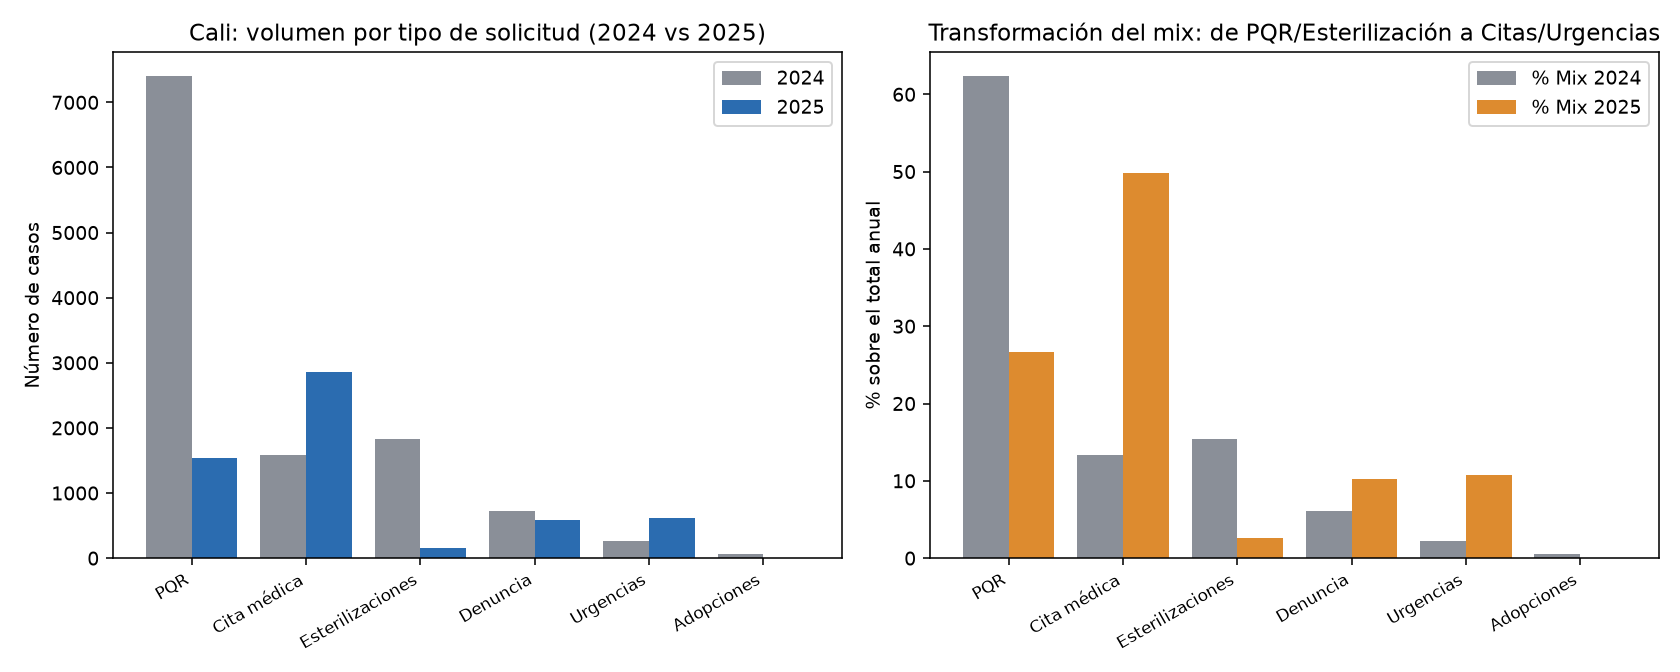

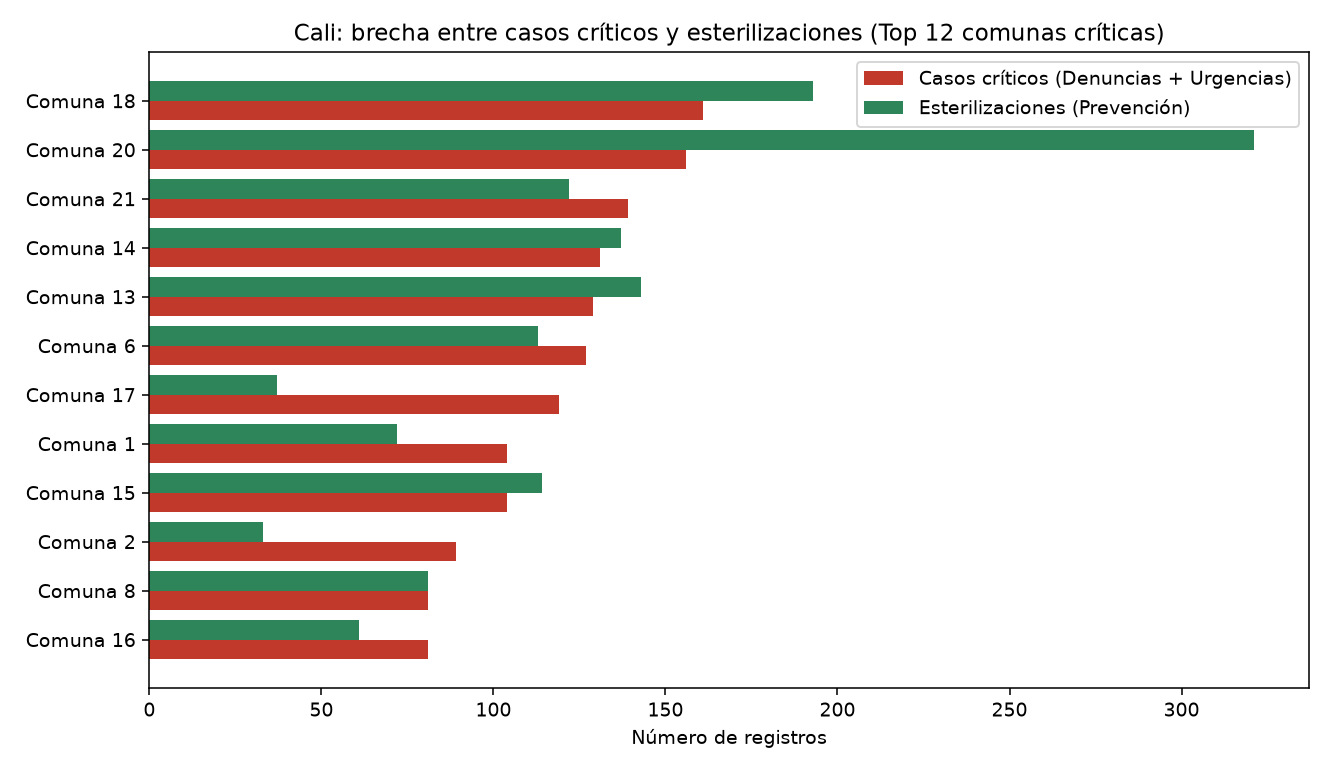

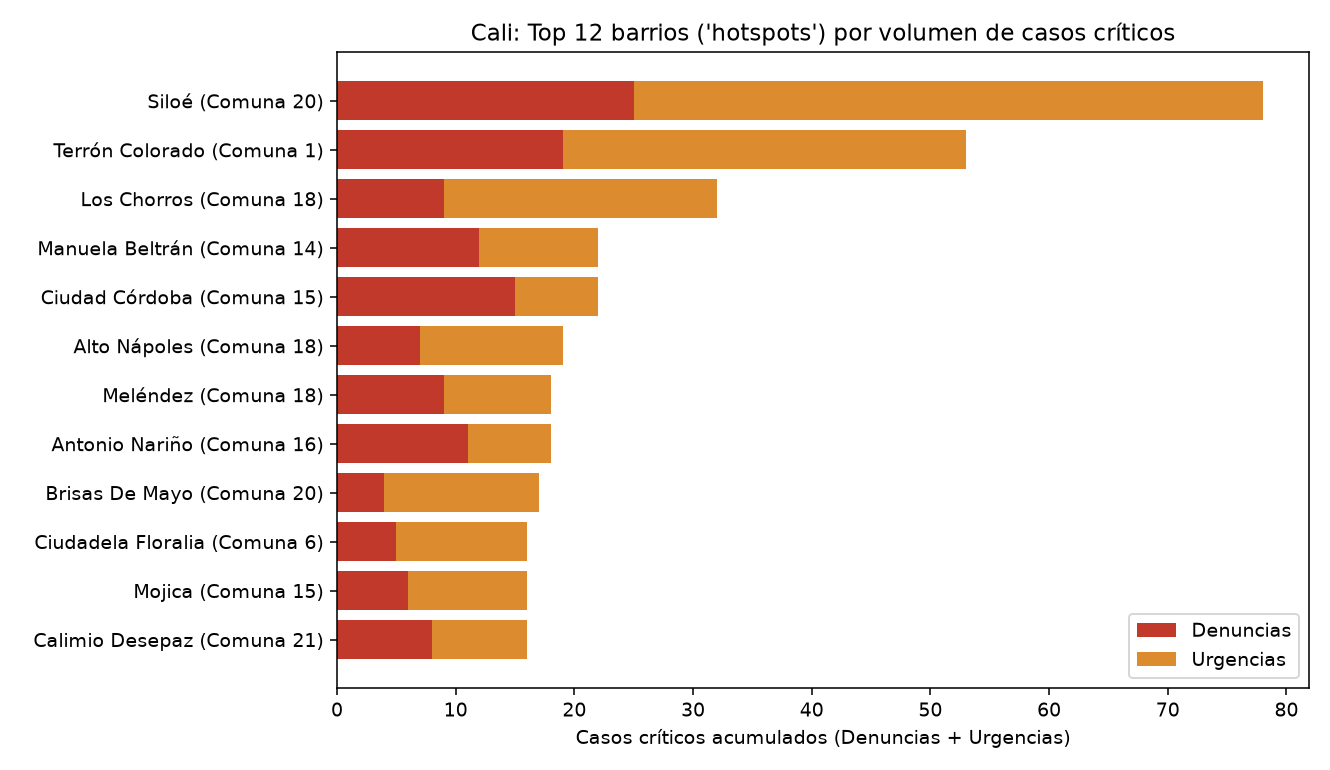

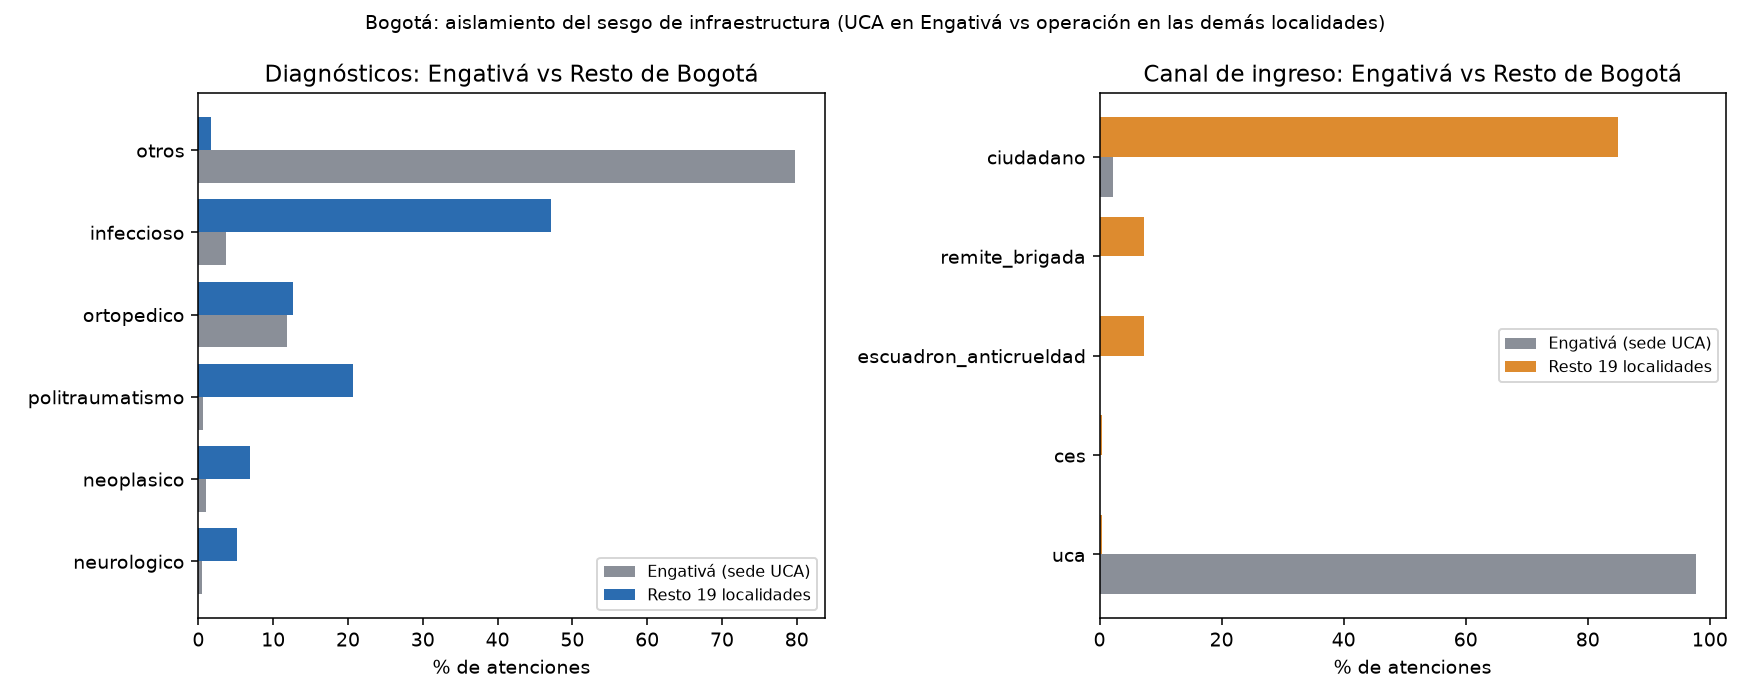

In [19]:
ev = p["evidencias_dir"]
graficos.grafica_casos_por_comuna(k_zona, ev)
graficos.grafica_evolucion_mensual(k_evol, ev)
graficos.grafica_urgencias_ciudades(k_urg, ev)
graficos.grafica_calidad(metricas, ev)
graficos.grafica_cambio_anual_servicios(k_cambio, ev)
graficos.grafica_brecha_prevencion(k_brecha, ev)
graficos.grafica_top_barrios(k_barrios, ev)
graficos.grafica_bogota_sesgo_uca(k_bog_sesgo, ev)
for f in sorted(os.listdir(ev)):
    if f.endswith(".png"):
        display(Image(os.path.join(ev, f)))

## 7. Resumen y conclusiones


In [20]:
pd.DataFrame({
    "capa": ["bronze (Cali)", "bronze (Bogotá)", "silver (Cali)", "silver (Bogotá)", "gold"],
    "filas": [len(bronze_cali), len(bronze_bogota["features"]), len(silver_cali), len(silver_bogota), len(gold_final)],
})

,capa,filas
0,bronze (Cali),17642
1,bronze (Bogotá),20
2,silver (Cali),17642
3,silver (Bogotá),20
4,gold,404


In [21]:
# Conclusiones calculadas con los datos
sin = limpieza_cali.SIN_DATO
top3 = k_zona[k_zona["zona"] != sin].head(3)
print("Zonas con más casos registrados:", ", ".join(f"{r.zona} ({int(r.casos_total)})" for r in top3.itertuples()))
if k_zona["casos_por_10k_hab"].notna().any():
    t = k_zona.dropna(subset=["casos_por_10k_hab"]).sort_values("casos_por_10k_hab", ascending=False).head(3)
    print("Mayor tasa por 10.000 hab.:", ", ".join(f"{r.zona} ({r.casos_por_10k_hab})" for r in t.itertuples()))
pr = k_prio.head(3)
print("Prioridad territorial más alta:", ", ".join(f"{r.zona} ({r.indice_priorizacion})" for r in pr.itertuples()))
urg = k_comp[k_comp["comparable"] == True].iloc[0]
print("Urgencias: Cali", int(urg["casos_cali_total"]), "| Bogotá", int(urg["casos_bogota_corte_2025_06_30"]))

Zonas con más casos registrados: Comuna 20 (2310), Comuna 18 (1441), Comuna 13 (1146)
Mayor tasa por 10.000 hab.: Villacarmelo (1442.54), Comuna 20 (325.16), Pance (318.57)
Prioridad territorial más alta: Comuna 20 (99.1), Comuna 18 (61.9), Comuna 21 (47.8)
Urgencias: Cali 879 | Bogotá 947


**Conclusiones**

1. **Dónde concentrar recursos:** el ranking de priorización combina casos, casos críticos (denuncias y urgencias) y la tasa por 10.000 habitantes normalizada por tipo de zona (urbana/rural), ubicando a las **Comunas 20, 18, 21, 13 y 14** en el top urbano y a **Villacarmelo y La Buitrera** en el top rural, con micro-focalización directa en los barrios **Siloé, Terrón Colorado y Los Chorros**.
2. **Alerta por caída de prevención en 2025:** entre 2024 y 2025 las esterilizaciones cayeron un **-91,8 %** (de 1.822 a 149) mientras las urgencias subieron **+137,7 %** y las citas médicas **+81,3 %**. Además, comunas como la **17, 2 y 22** demandan principalmente control de maltrato/denuncias, mientras **Comuna 20, 1 y 18** requieren brigadas clínicas y de esterilización.
3. **Calidad del dato accionable por canal:** el **81,2 % de los registros sin comuna** proviene de **PQR** y el **80,2 % de los registros sin barrio** se concentra entre **PQR (63,2 %) y Esterilizaciones (17,0 %)**. Exigir estos campos en esos dos canales permitirá alcanzar las metas del OKR 3 en origen.
4. **Cali y Bogotá (aislamiento del sesgo UCA):** solo "Urgencias" es comparable (Cali 879 en 2024-2025 vs. Bogotá 947 a corte 30/06/2025). Al separar el sesgo de la UCA en Engativá (79,7 % diagnóstico "Otros"), se observa que en las otras 19 localidades de Bogotá el **84,9 % proviene de reporte ciudadano** y predominan los casos **infecciosos (47,1 %) y politraumatismos (20,6 %)**.